In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
from load_data import load_novels

df = load_novels(ROOT / "data" / "raw")
print(f"Total documents loaded: {len(df)}")

Total documents loaded: 10


In [7]:
sample_text = df['raw_text'].iloc[0][:30000]
tokens = sample_text.split()
types = set(tokens)
print(f"Sample Tokens (total words): {len(tokens)}")
print(f"Sample Types (unique words): {len(types)}")
print(f"Type-Token Ratio: {len(types)/len(tokens):.4f}")

Sample Tokens (total words): 5252
Sample Types (unique words): 2008
Type-Token Ratio: 0.3823


The sample yields 5,252 tokens and 2,008 types (TTR ≈ 0.3823); note that TTR shrinks as sample size grows, so it is only comparable across equal-length samples.

In [3]:
df['word_count'] = df['raw_text'].apply(lambda x: len(x.split()))
avg_length = df['word_count'].mean()
print(f"Average document length: {avg_length:,.0f} words")
df[['title', 'word_count']].sort_values('word_count', ascending=False)

Average document length: 127,738 words


,title,word_count
5,Moby Dick,215845
4,Jane Eyre,188435
3,Great Expectations,187515
0,A Tale of Two Cities,138934
6,Pride and Prejudice,130416
9,Wuthering Heights,118978
7,The Adventures of Sherlock Holmes,107558
8,The Picture of Dorian Gray,82029
2,Frankenstein,78106
1,Alice in Wonderland,29569


In [6]:
print("--- EXAMPLE 1: First 400 characters of Novel 1 ---")
print(repr(df['raw_text'].iloc[0][:400]))

print("\n--- EXAMPLE 2: First 400 characters of Novel 2 ---")
print(repr(df['raw_text'].iloc[1][:400]))

print("\n--- EXAMPLE 3: First 400 characters of Novel 3 ---")
print(repr(df['raw_text'].iloc[2][:400]))


--- EXAMPLE 1: First 400 characters of Novel 1 ---
'The Project Gutenberg eBook of A Tale of Two Cities\n    \nThis eBook is for the use of anyone anywhere in the United States and\nmost other parts of the world at no cost and with almost no restrictions\nwhatsoever. You may copy it, give it away or re-use it under the terms\nof the Project Gutenberg License included with this eBook or online\nat www.gutenberg.org. If you are not located in the United St'

--- EXAMPLE 2: First 400 characters of Novel 2 ---
"The Project Gutenberg eBook of Alice's Adventures in Wonderland\n    \nThis eBook is for the use of anyone anywhere in the United States and\nmost other parts of the world at no cost and with almost no restrictions\nwhatsoever. You may copy it, give it away or re-use it under the terms\nof the Project Gutenberg License included with this eBook or online\nat www.gutenberg.org. If you are not located in t"

--- EXAMPLE 3: First 400 characters of Novel 3 ---
'The Project Gutenberg eBoo

All three files open with the Project Gutenberg license header instead of the story: boilerplate sentences, 
a URL (www.gutenberg.org), and irregular whitespace such as \n \n (newline + indented blank lines). 
The repr() output exposes these hidden characters, showing the raw text is unnormalized. 
This metadata must be stripped before tokenization, or license vocabulary will pollute the frequency counts and the dialogue/vocabulary analysis.

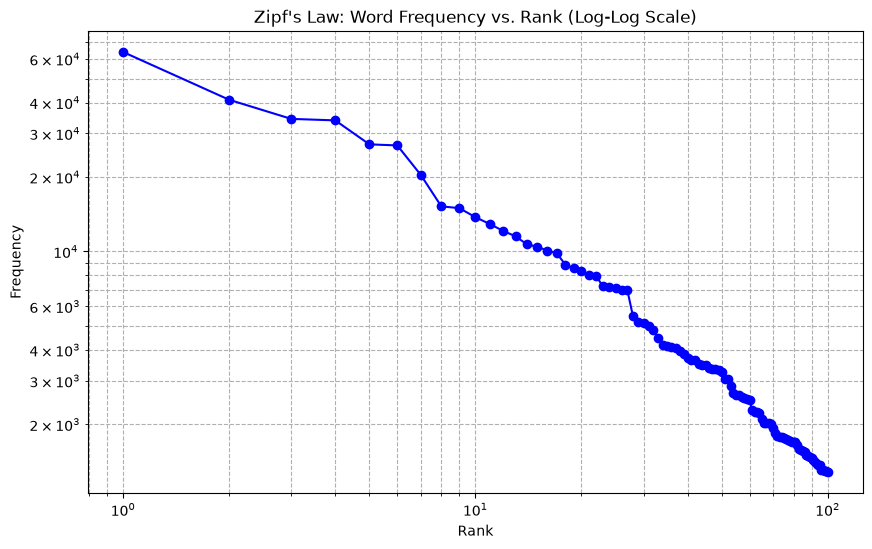

In [5]:
all_words = [word.lower() for text in df['raw_text'] for word in text.split()]
word_freq = Counter(all_words)
most_common = word_freq.most_common(100)

ranks = range(1, 101)
frequencies = [freq for word, freq in most_common]

plt.figure(figsize=(10, 6))
plt.loglog(ranks, frequencies, marker='o', linestyle='-', color='b')
plt.title("Zipf's Law: Word Frequency vs. Rank (Log-Log Scale)")
plt.xlabel("Rank")
plt.ylabel("Frequency")
plt.grid(True, which="both", ls="--")
plt.show()



The corpus follows a classic Zipfian distribution: a handful of function words 
dominate — "the" alone occurs ~65,000 times — while frequency falls roughly inversely with rank, reaching only ~1,300 occurrences 
by rank 100. The near-straight line on the log-log scale confirms the power-law relationship, with the
vast majority of the vocabulary living in the long tail of rare words.